# 06 - Clustering inside the large Nice classes

*Suggested part for Itamar.*

Notebook 04 showed that most clusters follow the Nice classes, but class 5 split by its goods text into groups with
very different failure rates. This notebook checks that idea for the largest classes: inside one class, does the
goods text reveal sub-groups that fail at different rates?

For each class: TF-IDF on the goods description of the applications in that class, TruncatedSVD, K-Means++ with k
chosen by silhouette, and then the failure rate of each sub-group. A chi-square test checks whether the failure rate
really differs between the sub-groups, and Cramér's V gives the size of the difference.

## Settings

In [1]:
CLASSES = [5, 9, 25, 35, 42]     # large classes to split
K_RANGE = range(2, 9)
SVD_COMPONENTS = 20
SILHOUETTE_SAMPLE = 5_000
RANDOM_STATE = 42

In [2]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ROOT = Path.cwd().parent
FIG, OUT = ROOT / "figures", ROOT / "outputs"
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

feats = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
train = feats[feats["is_train"]].reset_index(drop=True)   # training years only, like notebook 04
stop_words = list(ENGLISH_STOP_WORDS | {"class", "classes", "included", "including", "goods", "use"})

## 1. Split each class

In [3]:
def split_class(nice_class):
    g = train[train[f"nice_{nice_class}"] == 1].reset_index(drop=True)
    tfidf = TfidfVectorizer(stop_words=stop_words, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
                            min_df=5, max_features=10000, sublinear_tf=True)
    tf = tfidf.fit_transform(g["goods_text"])
    Z = normalize(TruncatedSVD(SVD_COMPONENTS, random_state=RANDOM_STATE).fit_transform(tf))

    rng = np.random.default_rng(RANDOM_STATE)
    idx = rng.choice(len(g), min(SILHOUETTE_SAMPLE, len(g)), replace=False)
    sil = {}
    for k in K_RANGE:
        lab = KMeans(k, n_init=5, random_state=RANDOM_STATE).fit_predict(Z)
        sil[k] = silhouette_score(Z[idx], lab[idx])
    k = max(sil, key=sil.get)
    g["sub"] = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)

    terms = np.array(tfidf.get_feature_names_out())
    profile = []
    for s, sg in g.groupby("sub"):
        mean_tf = np.asarray(tf[sg.index].mean(axis=0)).ravel()
        profile.append({"class": nice_class, "sub-group": s, "size": len(sg),
                        "failure_rate": sg["failed"].mean(),
                        "top terms": ", ".join(terms[mean_tf.argsort()[::-1][:6]])})
    ct = pd.crosstab(g["sub"], g["failed"])
    chi2, p, _, _ = chi2_contingency(ct)
    summary = {"class": nice_class, "applications": len(g), "class failure rate": g["failed"].mean(),
               "k": k, "silhouette": sil[k],
               "lowest sub-group rate": g.groupby("sub")["failed"].mean().min(),
               "highest sub-group rate": g.groupby("sub")["failed"].mean().max(),
               "chi2 p-value": p, "cramers_v": np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))}
    return pd.DataFrame(profile), summary

profiles, summaries = [], []
for c in CLASSES:
    prof, summ = split_class(c)
    profiles.append(prof)
    summaries.append(summ)
profiles = pd.concat(profiles, ignore_index=True)
summary = pd.DataFrame(summaries).set_index("class")
summary.round(3)

,applications,class failure rate,k,silhouette,lowest sub-group rate,highest sub-group rate,chi2 p-value,cramers_v
class,,,,,,,,
5,18149,0.098,8,0.234,0.040,0.214,0.0,0.157
9,28295,0.140,8,0.153,0.090,0.209,0.0,0.114
25,13347,0.162,8,0.318,0.082,0.243,0.0,0.139
35,17173,0.169,8,0.149,0.096,0.335,0.0,0.176
42,13967,0.176,8,0.139,0.097,0.290,0.0,0.189


In [4]:
pd.set_option("display.max_colwidth", 80)
profiles.sort_values(["class", "failure_rate"]).round(3)

,class,sub-group,size,failure_rate,top terms
5,5,5,3482,0.040,"diseases, treatment, disorders, pharmaceutical, preparations, prevention"
3,5,3,989,0.078,"fungicides, herbicides, insecticides, vermin, destroying, pesticides"
1,5,1,2830,0.080,"pharmaceutical, preparations, treatment, cancer, substances, prevention"
7,5,7,2909,0.092,"human, pharmaceutical, preparations, products, veterinary, vaccines"
6,5,6,1914,0.098,"medical, diagnostic, purposes, reagents, research, preparations"
4,5,4,1912,0.104,"skin, medicated, care, preparations, hair, cosmetic"
2,5,2,2411,0.134,"supplements, nutritional, food, dietary, vitamins, dietetic"
0,5,0,1702,0.214,"medical, materials, dental, dressings, sanitary, plasters"
12,9,4,2609,0.090,"lenses, sunglasses, spectacles, cases, frames, contact"
15,9,7,4797,0.099,"electric, apparatus, control, electronic, electrical, systems"


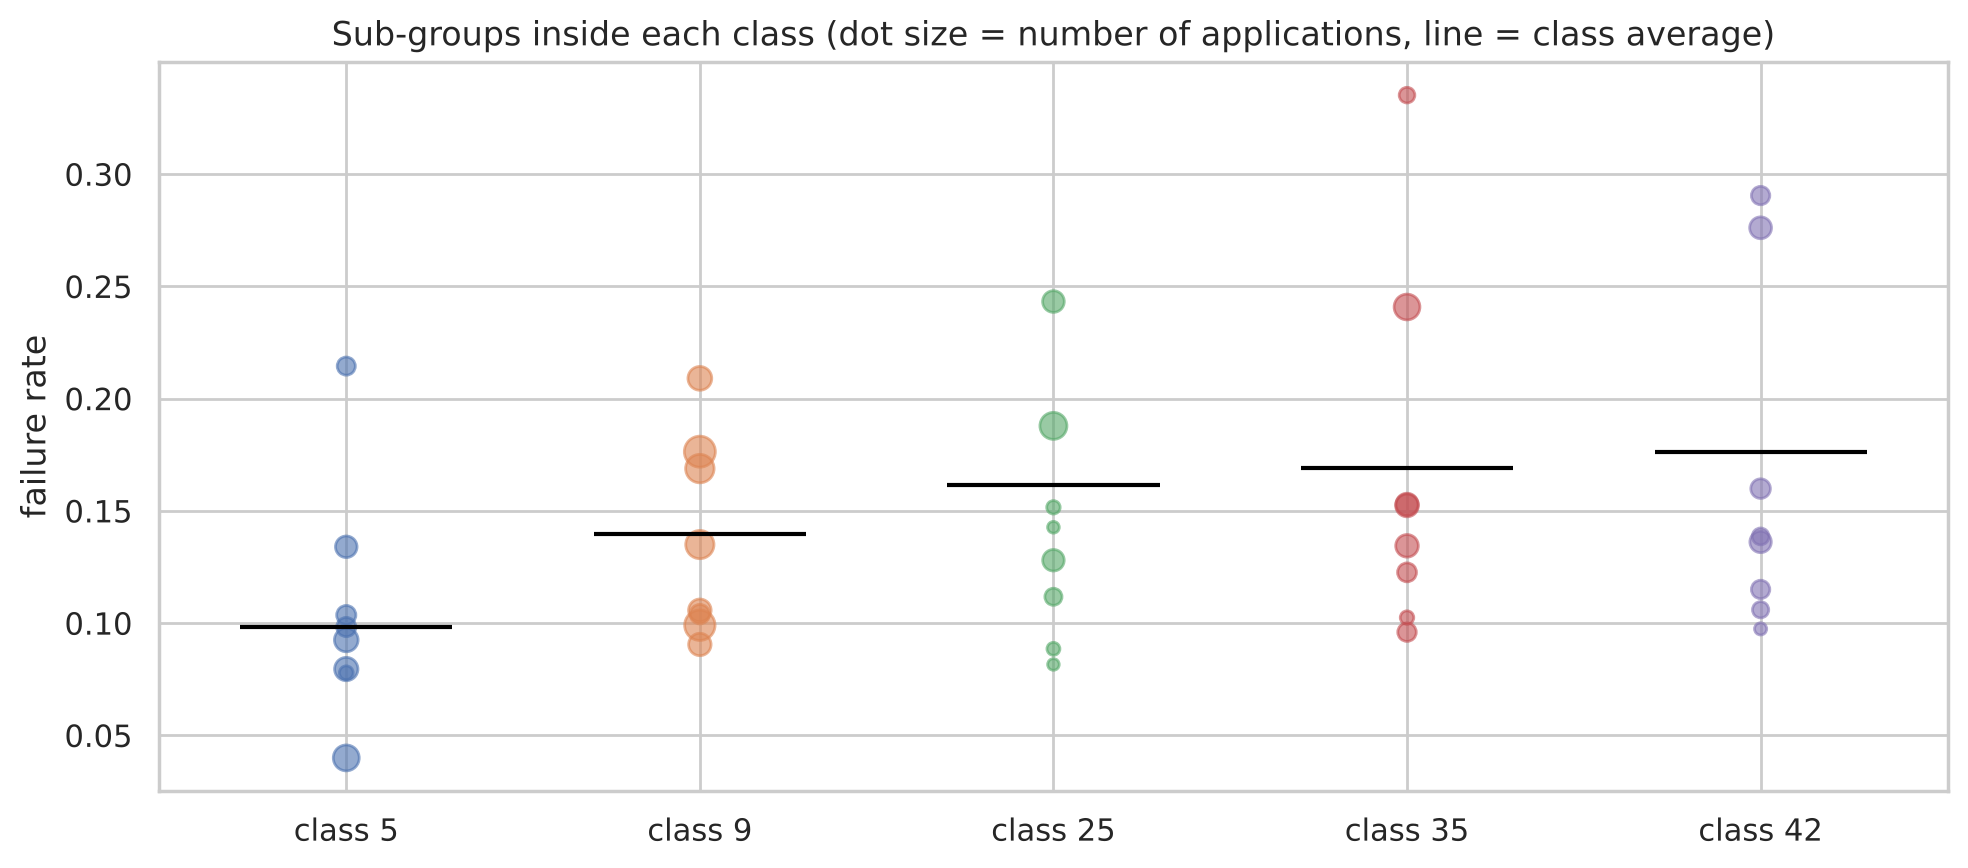

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, c in enumerate(CLASSES):
    p = profiles[profiles["class"] == c]
    ax.scatter([i] * len(p), p["failure_rate"], s=p["size"] / 40, alpha=0.6)
    ax.hlines(summary.loc[c, "class failure rate"], i - 0.3, i + 0.3, color="black")
ax.set_xticks(range(len(CLASSES)), [f"class {c}" for c in CLASSES])
ax.set_ylabel("failure rate")
ax.set_title("Sub-groups inside each class (dot size = number of applications, line = class average)")
plt.tight_layout()
plt.savefig(FIG / "within_class_subgroups.png", dpi=120)
plt.show()

profiles.to_csv(OUT / "within_class_subgroups.csv", index=False)

**Findings.** In all five classes the sub-groups fail at clearly different rates (chi-square p < 0.001,
Cramér's V 0.11-0.19, larger than most single features in notebook 01). Inside one class the rate can vary three- to eightfold:

| Class | Lowest sub-group | Highest sub-group |
|---|---|---|
| 5 | pharmaceuticals for diseases, 4% | dental and medical materials, plasters, 21% |
| 9 | glasses and lenses, 9% | general "apparatus for recording / processing data", 21% |
| 25 | (cosmetics filed together with clothing), 8% | general "clothing, footwear, headwear", 24% |
| 35 | (vehicles and machines in a class 35 filing), 10% | "business administration, office functions", 34% |
| 42 | chemicals and materials, 10% | general web and internet services, 29% |

A pattern worth checking: the highest-failure sub-groups use very general wording that looks like the official
class heading ("business administration, office functions", "clothing, footwear, headgear"). One possible reason is
that these are often applications filed without much preparation, but this needs to be checked by looking at examples.

Note: k = 8 was chosen in every class, the top of the range tried. The silhouette keeps rising with k for text,
so 8 is a practical limit for readability, not a true optimum.

## Ideas to continue

- Try other k values or other methods (Agglomerative with cosine distance) and see if the same sub-groups appear.
- Check whether the sub-group helps the classifier more than the class-wide clusters did in notebook 04.
- Look at a few applications from the highest- and lowest-failure sub-groups to understand what separates them.